# A/B Testing Analysis: Facebook vs. AdWords Marketing Campaign



## Project Overview: Marketing Campaign A/B Testing (`Facebook` vs. `AdWords`)


### Objective
Compare daily performance, conversion efficiency, and time-based patterns between **Facebook** and **AdWords** ad campaigns to guide budget and targeting decisions.

### Dataset Columns Description (`marketing_campaign_data.csv`)

- **`Date`**: Campaign recording date (365 daily rows from `2019-01-01` to `2019-12-31`).

#### Facebook Campaign Metrics
- **`Facebook_Views`**: Total daily impressions/views served on Facebook.
- **`Facebook_Clicks`**: Total daily clicks received on Facebook ads.
- **`Facebook_Conversions`**: Total daily conversions generated from Facebook clicks.
- **`Facebook_Cost_per_Ad`**: Daily spend/cost incurred on Facebook ads.
- **`Facebook_CTR`**: Click-Through Rate (`Facebook_Clicks / Facebook_Views`).
- **`Facebook_Conversion_Rate`**: Conversion Rate (`Facebook_Conversions / Facebook_Clicks`).
- **`Facebook_Cost_per_Click`**: Average cost per click (`Facebook_Cost_per_Ad / Facebook_Clicks`).
- **`Facebook_Cost_per_Conversion`**: Average cost per conversion (`Facebook_Cost_per_Ad / Facebook_Conversions`).

#### AdWords Campaign Metrics
- **`AdWords_Views`**: Total daily impressions/views served on AdWords.
- **`AdWords_Clicks`**: Total daily clicks received on AdWords ads.
- **`AdWords_Conversions`**: Total daily conversions generated from AdWords clicks.
- **`AdWords_Cost_per_Ad`**: Daily spend/cost incurred on AdWords ads.
- **`AdWords_CTR`**: Click-Through Rate (`AdWords_Clicks / AdWords_Views`).
- **`AdWords_Conversion_Rate`**: Conversion Rate (`AdWords_Conversions / AdWords_Clicks`).
- **`AdWords_Cost_per_Click`**: Average cost per click (`AdWords_Cost_per_Ad / AdWords_Clicks`).
- **`AdWords_Cost_per_Conversion`**: Average cost per conversion (`AdWords_Cost_per_Ad / AdWords_Conversions`).

In [1]:
# Importing Libraries

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import seaborn as sns
from statsmodels.tsa.stattools import coint
import scipy.stats as st
import warnings


##  Loading & Exploring the Dataset

In [2]:
df = pd.read_csv('/content/marketing_campaign_data.csv')

In [3]:
df.head()

,Date,Facebook_Views,Facebook_Clicks,Facebook_Conversions,Facebook_Cost_per_Ad,Facebook_CTR,Facebook_Conversion_Rate,Facebook_Cost_per_Click,Facebook_Cost_per_Conversion,AdWords_Views,AdWords_Clicks,AdWords_Conversions,AdWords_Cost_per_Ad,AdWords_CTR,AdWords_Conversion_Rate,AdWords_Cost_per_Click,AdWords_Cost_per_Conversion
0,2019-01-01,216,18,8,26.00,8.33,44.44,1.44,3.25,867,53,4,87.43,6.11,7.55,1.65,21.86
1,2019-01-02,367,30,10,79.10,8.17,33.33,2.64,7.91,720,36,4,55.55,5.00,11.11,1.54,13.89
2,2019-01-03,306,25,7,52.83,8.17,28.00,2.11,7.55,1033,61,5,109.30,5.91,8.20,1.79,21.86
3,2019-01-04,209,14,9,71.93,6.70,64.29,5.14,7.99,1205,73,6,105.77,6.06,8.22,1.45,17.63
4,2019-01-05,313,26,7,54.30,8.31,26.92,2.09,7.76,836,52,8,85.92,6.22,15.38,1.65,10.74


In [ ]:
df.tail ()

,Date,Facebook_Views,Facebook_Clicks,Facebook_Conversions,Facebook_Cost_per_Ad,Facebook_CTR,Facebook_Conversion_Rate,Facebook_Cost_per_Click,Facebook_Cost_per_Conversion,AdWords_Views,AdWords_Clicks,AdWords_Conversions,AdWords_Cost_per_Ad,AdWords_CTR,AdWords_Conversion_Rate,AdWords_Cost_per_Click,AdWords_Cost_per_Conversion
360,2019-12-27,806,64,14,101.73,7.94,21.88,1.59,7.27,523,25,8,44.55,4.78,32.00,1.78,5.57
361,2019-12-28,754,66,14,102.71,8.75,21.21,1.56,7.34,543,24,4,42.23,4.42,16.67,1.76,10.56
362,2019-12-29,560,48,14,101.83,8.57,29.17,2.12,7.27,607,28,3,46.06,4.61,10.71,1.64,15.35
363,2019-12-30,756,67,16,118.05,8.86,23.88,1.76,7.38,535,25,1,34.19,4.67,4.00,1.37,34.19
364,2019-12-31,1010,88,19,144.02,8.71,21.59,1.64,7.58,992,48,4,61.39,4.84,8.33,1.28,15.35


In [ ]:
df.shape

(365, 17)

In [ ]:
df.columns

Index(['Date', 'Facebook_Views', 'Facebook_Clicks', 'Facebook_Conversions',
       'Facebook_Cost_per_Ad', 'Facebook_CTR', 'Facebook_Conversion_Rate',
       'Facebook_Cost_per_Click', 'Facebook_Cost_per_Conversion',
       'AdWords_Views', 'AdWords_Clicks', 'AdWords_Conversions',
       'AdWords_Cost_per_Ad', 'AdWords_CTR', 'AdWords_Conversion_Rate',
       'AdWords_Cost_per_Click', 'AdWords_Cost_per_Conversion'],
      dtype='object')

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 365 entries, 0 to 364
Data columns (total 17 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Date                          365 non-null    object 
 1   Facebook_Views                365 non-null    int64  
 2   Facebook_Clicks               365 non-null    int64  
 3   Facebook_Conversions          365 non-null    int64  
 4   Facebook_Cost_per_Ad          365 non-null    float64
 5   Facebook_CTR                  365 non-null    float64
 6   Facebook_Conversion_Rate      365 non-null    float64
 7   Facebook_Cost_per_Click       365 non-null    float64
 8   Facebook_Cost_per_Conversion  365 non-null    float64
 9   AdWords_Views                 365 non-null    int64  
 10  AdWords_Clicks                365 non-null    int64  
 11  AdWords_Conversions           365 non-null    int64  
 12  AdWords_Cost_per_Ad           365 non-null    float64
 13  AdWor

In [ ]:
df.isnull( ) .sum()

,0
Date,0
Facebook_Views,0
Facebook_Clicks,0
Facebook_Conversions,0
Facebook_Cost_per_Ad,0
Facebook_CTR,0
Facebook_Conversion_Rate,0
Facebook_Cost_per_Click,0
Facebook_Cost_per_Conversion,0
AdWords_Views,0


In [ ]:
df['Date']=pd.to_datetime(df['Date'])

In [ ]:
df.describe()

,Date,Facebook_Views,Facebook_Clicks,Facebook_Conversions,Facebook_Cost_per_Ad,Facebook_CTR,Facebook_Conversion_Rate,Facebook_Cost_per_Click,Facebook_Cost_per_Conversion,AdWords_Views,AdWords_Clicks,AdWords_Conversions,AdWords_Cost_per_Ad,AdWords_CTR,AdWords_Conversion_Rate,AdWords_Cost_per_Click,AdWords_Cost_per_Conversion
count,365,365.000000,365.000000,365.000000,365.000000,365.000000,365.000000,365.000000,365.000000,365.000000,365.000000,365.000000,365.000000,365.000000,365.000000,365.000000,365.000000
mean,2019-07-02 00:00:00,524.380822,43.646575,11.632877,88.256603,8.375068,30.488575,2.333288,7.622301,794.991781,40.821918,4.994521,61.768712,5.233534,13.619753,1.516712,13.723507
min,2019-01-01 00:00:00,128.000000,12.000000,5.000000,26.000000,6.700000,14.630000,1.180000,3.250000,244.000000,15.000000,1.000000,18.080000,4.000000,2.270000,1.200000,3.170000
25%,2019-04-02 00:00:00,355.000000,30.000000,9.000000,70.150000,8.000000,22.950000,1.720000,7.370000,554.000000,29.000000,4.000000,42.940000,4.640000,9.090000,1.380000,9.120000
50%,2019-07-02 00:00:00,509.000000,43.000000,12.000000,88.190000,8.370000,26.830000,2.030000,7.590000,769.000000,41.000000,5.000000,59.670000,5.240000,12.000000,1.530000,12.680000
75%,2019-10-01 00:00:00,682.000000,57.000000,14.000000,101.500000,8.750000,33.330000,2.530000,7.860000,1005.000000,52.000000,6.000000,79.250000,5.850000,16.130000,1.660000,16.290000
max,2019-12-31 00:00:00,1252.000000,99.000000,21.000000,160.620000,9.920000,83.330000,6.900000,8.840000,1898.000000,85.000000,10.000000,130.320000,6.500000,53.330000,1.800000,74.460000
std,NaN,238.223254,19.335770,3.227120,23.562220,0.581515,11.680315,0.949123,0.463723,330.650188,15.695193,1.889814,24.378213,0.700817,6.756848,0.170948,7.118722


##  Campaign Distribution Analysis (Histograms)

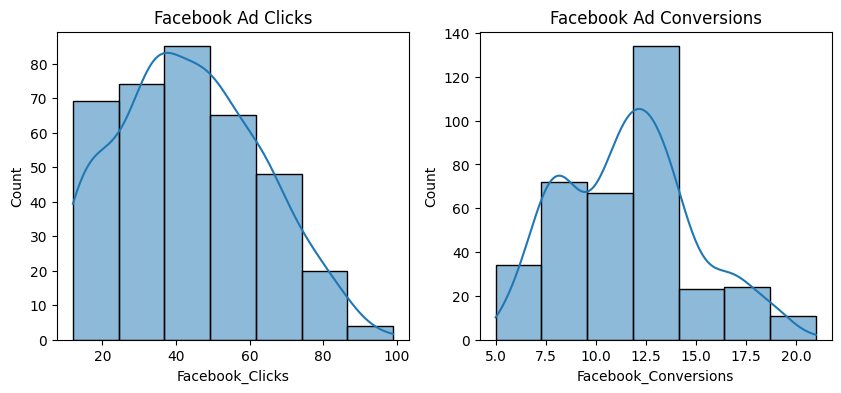

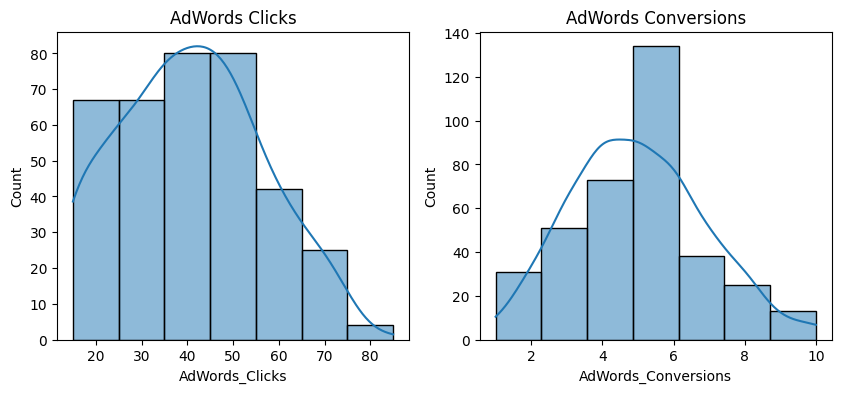

In [4]:
#  Comparing Campaign Performance (Histograms)
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.title("Facebook Ad Clicks")
sns.histplot(df["Facebook_Clicks"], bins=7, edgecolor="k", kde=True)

plt.subplot(1, 2, 2)
plt.title("Facebook Ad Conversions")
sns.histplot(df["Facebook_Conversions"], bins=7, edgecolor="k", kde=True)

# 3. Comparing AdWords Campaign Performance (Histograms)
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.title("AdWords Clicks")
sns.histplot(df["AdWords_Clicks"], bins=7, edgecolor="k", kde=True)

plt.subplot(1, 2, 2)
plt.title("AdWords Conversions")
sns.histplot(df["AdWords_Conversions"], bins=7, edgecolor="k", kde=True)



plt.show()

Facebook Ad Clicks (Facebook_Clicks): Roughly bell-shaped with a slight right tail. Most days sit around 30 to 60 clicks (mean 43.65, median 43.0), stretching up to 99 on peak days.

Facebook Ad Conversions (Facebook_Conversions): Concentrated around 10 to 15 conversions per day (mean 11.63, median 12.0), with a noticeable peak near 12–13 and a smaller tail reaching 21.

AdWords Clicks (AdWords_Clicks): Fairly tight, slightly right-skewed distribution peaking around 30 to 50 clicks (mean 40.82, median 41.0), ranging from 15 to 85.

AdWords Conversions (AdWords_Conversions): Right-skewed and clustered at lower counts—most days fall between 4 and 6 conversions (mean 4.99, median 5.0), maxing out at 10.

##  Conversion Category Breakdown

In [5]:
# Creating function to calculate the category for the conversions
def create_conversion_category(conversion_col):
    category = []
    for conversion in conversion_col:
        if conversion < 6:
            category.append('less than 6')
        elif 6 <= conversion < 11:
            category.append('6 - 10')
        elif 11 <= conversion < 16:
            category.append('10 - 15')
        else:
            category.append('more than 15')
    return category

# Applying function to different campaign's conversions using the exact column names
df['Facebook_Conversion_Category'] = create_conversion_category(df['Facebook_Conversions'])
df['AdWords_Conversion_Category'] = create_conversion_category(df['AdWords_Conversions'])

# Displaying the result
df[['Facebook_Conversions', 'Facebook_Conversion_Category', 'AdWords_Conversions', 'AdWords_Conversion_Category']].head()

,Facebook_Conversions,Facebook_Conversion_Category,AdWords_Conversions,AdWords_Conversion_Category
0,8,6 - 10,4,less than 6
1,10,6 - 10,4,less than 6
2,7,6 - 10,5,less than 6
3,9,6 - 10,6,6 - 10
4,7,6 - 10,8,6 - 10


##  Clicks vs. Conversions & Correlation Analysis

In [6]:
df['Facebook_Conversion_Category'].value_counts()

,count
Facebook_Conversion_Category,
10 - 15,189
6 - 10,128
more than 15,47
less than 6,1


In [7]:
df['AdWords_Conversion_Category'].value_counts()

,count
AdWords_Conversion_Category,
less than 6,226
6 - 10,139


In [8]:
# 1. Creating count DataFrames for each platform
facebook = df['Facebook_Conversion_Category'].value_counts().reset_index()
facebook.columns = ['Category', 'Facebook_Count']

adwords = df['AdWords_Conversion_Category'].value_counts().reset_index()
adwords.columns = ['Category', 'AdWords_Count']

# 2. Merging the Facebook and AdWords conversion category DataFrames
category_df = pd.merge(facebook, adwords, on='Category', how='outer').fillna(0)
category_df

,Category,Facebook_Count,AdWords_Count
0,10 - 15,189,0.0
1,6 - 10,128,139.0
2,less than 6,1,226.0
3,more than 15,47,0.0


In [9]:
#  Reordering rows in logical ascending order safely
logical_order = ['less than 6', '6 - 10', '10 - 15', 'more than 15']
category_df['Category'] = pd.Categorical(category_df['Category'], categories=logical_order, ordered=True)
category_df = category_df.sort_values('Category').reset_index(drop=True)
category_df

,Category,Facebook_Count,AdWords_Count
0,less than 6,1,226.0
1,6 - 10,128,139.0
2,10 - 15,189,0.0
3,more than 15,47,0.0


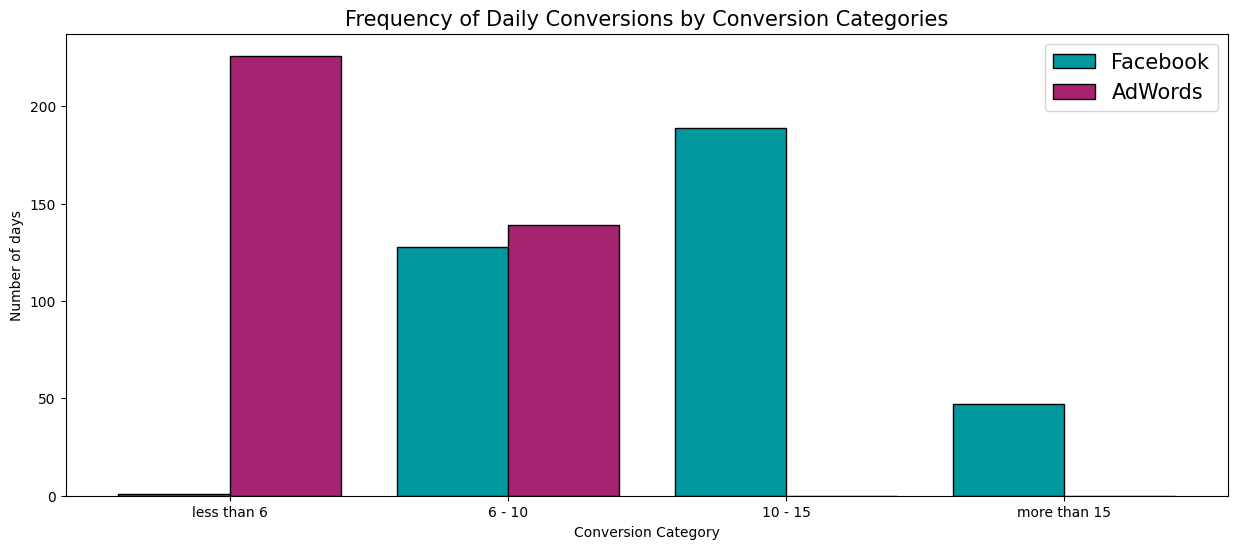

In [10]:
#  Plotting the side-by-side bar chart
X_axis = np.arange(len(category_df))
plt.figure(figsize=(15, 6))

plt.bar(X_axis - 0.2, category_df['Facebook_Count'], 0.4, label='Facebook', color='#03989E', linewidth=1, edgecolor='k')
plt.bar(X_axis + 0.2, category_df['AdWords_Count'], 0.4, label='AdWords', color='#A62372', linewidth=1, edgecolor='k')

plt.xticks(X_axis, category_df['Category'])
plt.xlabel("Conversion Category")
plt.ylabel("Number of days")
plt.title("Frequency of Daily Conversions by Conversion Categories", fontsize=15)
plt.legend(fontsize=15)
plt.show()

Across the 365 days in the dataset, **Facebook** consistently achieves higher daily conversions than **AdWords**:

- **AdWords** is concentrated at the lower end, recording **less than 6** conversions on **226 days** (62%) and **6 – 10** conversions on **139 days** (~38%), with **0 days** above 10.
- **Facebook** peaks in the **10 – 15** range (**189 days**, ~52%), followed by **6 – 10** (**128 days**, ~35%) and **more than 15** (**47 days**, ~13%), with only **1 day** below 6.

Overall, Facebook shifts daily conversion volume substantially higher than AdWords (mean **11.63** vs. **4.99**).

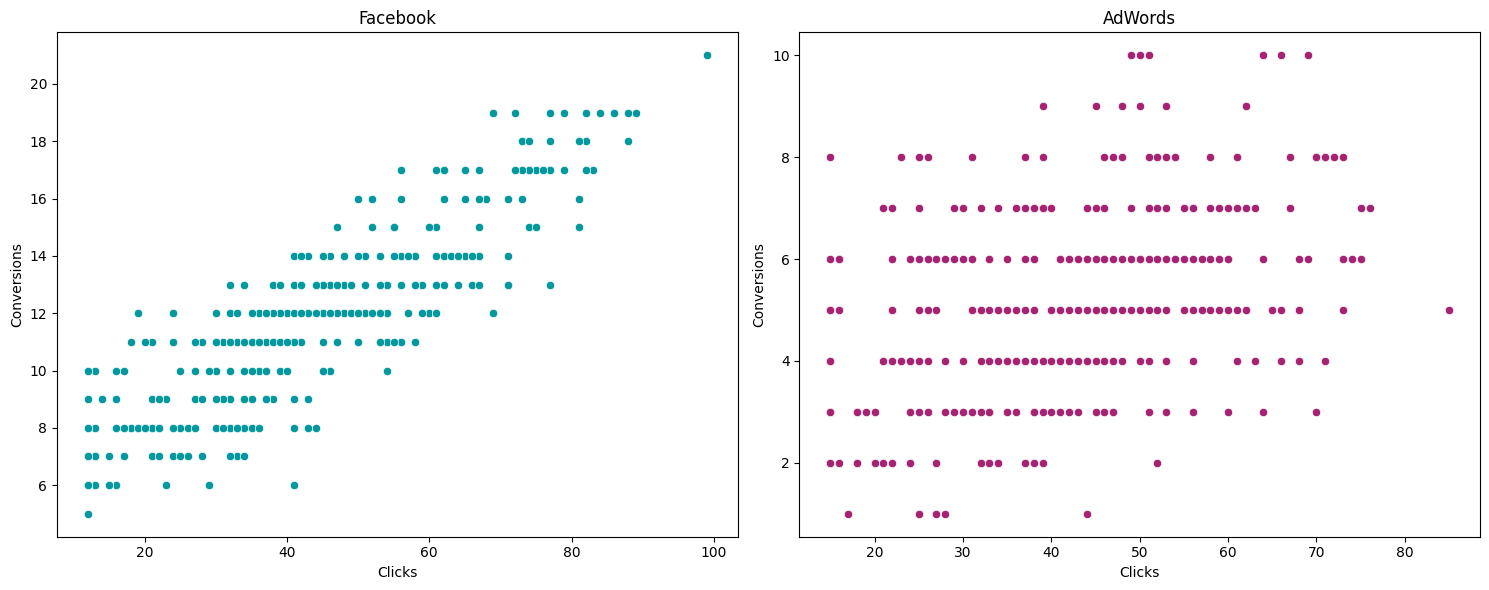

In [11]:
# Plotting scatter plots for Clicks vs Conversions
plt.figure(figsize=(15, 6))

plt.subplot(1, 2, 1)
plt.title('Facebook')
sns.scatterplot(x=df['Facebook_Clicks'], y=df['Facebook_Conversions'], color='#03989E')
plt.xlabel('Clicks')
plt.ylabel('Conversions')

plt.subplot(1, 2, 2)
plt.title('AdWords')
sns.scatterplot(x=df['AdWords_Clicks'], y=df['AdWords_Conversions'], color='#A62372')
plt.xlabel('Clicks')
plt.ylabel('Conversions')

plt.tight_layout()
plt.show()


### Clicks vs. Conversions

- **Facebook (Facebook_Clicks vs. Facebook_Conversions):** Clear positive upward trend—more clicks consistently bring more conversions, reaching up to **21** per day with a strong correlation (**r = 0.88**).
- **AdWords (AdWords_Clicks vs. AdWords_Conversions):** Much looser spread and weaker correlation (**r = 0.45**), with daily conversions staying between **1 and 10** regardless of higher click counts.

Overall, click volume drives conversions far more reliably on Facebook than on AdWords.

In [16]:
facebook_corr = df[["Facebook_Conversions", "Facebook_Clicks"]].corr()
facebook_corr

,Facebook_Conversions,Facebook_Clicks
Facebook_Conversions,1.000000,0.876392
Facebook_Clicks,0.876392,1.000000


In [17]:
adwords_corr = df[['AdWords_Conversions', 'AdWords_Clicks']].corr()
adwords_corr

,AdWords_Conversions,AdWords_Clicks
AdWords_Conversions,1.000000,0.449645
AdWords_Clicks,0.449645,1.000000


In [18]:
print("Correlation Coeff \n------------------")
print("Facebook :", round(facebook_corr.values[0, 1], 2))
print("Adwords  :", round(adwords_corr.values[0, 1], 2))

Correlation Coeff 
------------------
Facebook : 0.88
Adwords  : 0.45


### Correlation Coefficient (Clicks vs. Conversions)

- **Facebook (0.88):** Strong positive link—more clicks usually bring more conversions.
- **AdWords (0.45):** Weak-to-moderate link—more clicks do not reliably increase conversions.

## Hypothesis Testing (Two-Sample T-Test)

#Hypothesis Statements
 Advertising on Facebook will result in a greater number of conversions
compared to advertising on AdWords.

Null Hypothesis ($H_0$): There is no difference in the number of conversions between Facebook and AdWords, or the number of conversions from AdWords is greater than or equal to those from Facebook.$$H_0: \mu_{\text{Facebook}} \le \mu_{\text{AdWords}}$$Alternate Hypothesis ($H_1$): The number of conversions from Facebook is greater than the number of conversions from AdWords.$$H_1: \mu_{\text{Facebook}} > \mu_{\text{AdWords}}$$

In [20]:

print("Mean Conversion \n--------------")
print("Facebook :", round(df["Facebook_Conversions"].mean(), 2))
print("AdWords  :", round(df["AdWords_Conversions"].mean(), 2))

t_stats, p_value = st.ttest_ind(
    a=df["Facebook_Conversions"],
    b=df["AdWords_Conversions"],
    equal_var=False,
)
print("\nT statistic", t_stats, "\np-value", p_value)

# comparing the p value with the significance of 5% or 0.05
if p_value < 0.05:
  print("\np-value is less than significance value, Reject the null hypothesis")
else:
  print(
      "\np-value is greater than significance value, Accept the null hypothesis"
  )

Mean Conversion 
--------------
Facebook : 11.63
AdWords  : 4.99

T statistic 33.91289691327135 
p-value 1.9014554368564938e-140

p-value is less than significance value, Reject the null hypothesis


### T-Test Result (Facebook vs. AdWords Conversions)

- **Mean Conversions:** Facebook (**11.63**) vs. AdWords (**4.99**)
- **T-statistic:** 33.91
- **p-value:** 1.90e-140 (< 0.05)

**Conclusion:** Reject the null hypothesis—Facebook gets significantly more daily conversions than AdWords.

#** Regression Analysis**

### Linear Regression Analysis (Facebook Clicks vs. Conversions)

In [21]:


# Independent variable (Clicks) and Dependent variable (Conversions)
X = df[["Facebook_Clicks"]]
y = df[["Facebook_Conversions"]]

# Initializing and fitting the Linear Regression model
reg = LinearRegression()
reg.fit(X, y)
prediction = reg.predict(X)

# Model evaluation
r2 = r2_score(y, prediction) * 100
mse = mean_squared_error(y, prediction)
print("Accuracy (R2 Score):", round(r2, 2), "%")
print("Mean Squared Error:", round(mse, 2))

Accuracy (R2 Score): 76.81 %
Mean Squared Error: 2.41


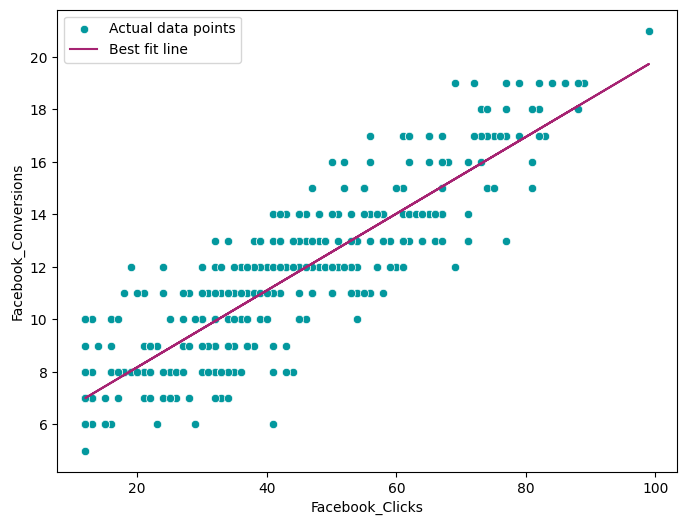

In [22]:
# Plotting the actual data points and the best-fit regression line
plt.figure(figsize=(8, 6))
sns.scatterplot(
    x=df["Facebook_Clicks"],
    y=df["Facebook_Conversions"],
    color="#03989E",
    label="Actual data points",
)
plt.plot(
    df["Facebook_Clicks"],
    prediction,
    color="#A62372",
    label="Best fit line",
)
plt.legend()
plt.show()

### Linear Regression Plot (Facebook Clicks vs. Conversions)

- The purple regression line slopes upward steadily, showing that higher daily **Facebook Clicks** consistently bring more conversions.
- Most points sit close to the line, matching the **76.81% R² score** and **2.41 MSE**.

In [23]:
# Predicting expected conversions for 50 and 80 clicks
print(
    f"For {50} Clicks, Expected Conversion :"
    f" {round(reg.predict([[50]])[0][0], 2)}"
)
print(
    f"For {80} Clicks, Expected Conversion :"
    f" {round(reg.predict([[80]])[0][0], 2)}"
)

For 50 Clicks, Expected Conversion : 12.56
For 80 Clicks, Expected Conversion : 16.95


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


### Expected Facebook Conversions from Regression

- **50 Clicks:** 12.56 expected conversions
- **80 Clicks:** 16.95 expected conversions

Higher daily Facebook clicks translate into a steady increase in predicted conversions.

In [33]:
# Filtering for Facebook campaign
# The data in df is already clean and numeric (as shown in df.info()), so string cleaning/slicing is not required.
# If you need to revert df back to its original columns, you can reload it from the CSV:

df['Date'] = pd.to_datetime(df['Date'])

# Directly rename and filter the columns to match the desired user-friendly names
df = df[[
    'Date',
    'Facebook_Views',
    'Facebook_Clicks',
    'Facebook_Conversions',
    'Facebook_Cost_per_Ad',
    'Facebook_CTR',
    'Facebook_Conversion_Rate',
    'Facebook_Cost_per_Click'
]].rename(columns={
    'Facebook_Views': 'Facebook Ad Views',
    'Facebook_Clicks': 'Facebook Ad Clicks',
    'Facebook_Conversions': 'Facebook Ad Conversions',
    'Facebook_Cost_per_Ad': 'Cost per Facebook Ad',
    'Facebook_CTR': 'Facebook Click-Through Rate (Clicks / View)',
    'Facebook_Conversion_Rate': 'Facebook Conversion Rate (Conversions / Clicks)',
    'Facebook_Cost_per_Click': 'Facebook Cost per Click (Ad Cost / Clicks)'
})

## Facebook Time-Series & Seasonality Analysis

In [34]:
# Extracting month and week day from the Date column
df['month'] = df['Date'].dt.month
df['week'] = df['Date'].dt.weekday

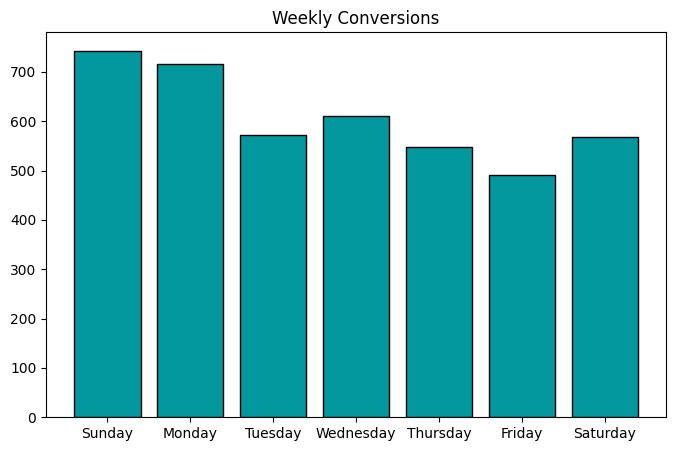

In [35]:
# Plotting Weekly Conversions
plt.figure(figsize=(8, 5))
plt.title('Weekly Conversions')
weekly_conversion = df.groupby('week')[['Facebook Ad Conversions']].sum()
week_names = [
    'Sunday',
    'Monday',
    'Tuesday',
    'Wednesday',
    'Thursday',
    'Friday',
    'Saturday',
]
plt.bar(
    week_names,
    weekly_conversion['Facebook Ad Conversions'],
    color='#03989E',
    edgecolor='k',
)
plt.show()

### Weekly Conversions — Insights & Recommendations

- **Peak Days:** **Sunday** (750 conversions) and **Monday** (~715 conversions) generate the highest total Facebook conversions[cite: 1].
- **Lowest Days:** **Friday** (490 conversions) records the lowest volume, followed by **Thursday** (550) and **Saturday** (~570)[cite: 1].
- **Note on Labels:** dt.weekday maps 0 = Monday through 6 = Sunday in pandas, so verify your week_names list order if you want exact day-of-week alignment.

**Recommendations:**
- Increase Facebook ad budget and bidding on **Sundays and Mondays** to capture peak conversion momentum.
- Review ad creatives or reduce spend on **Fridays** where conversion volume dips.

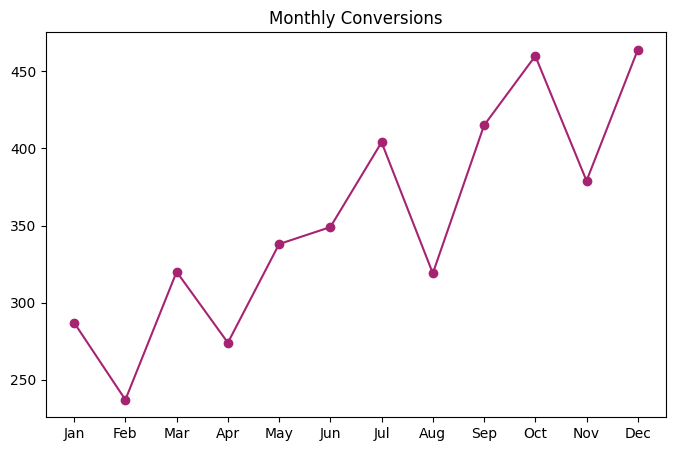

In [36]:
# Plotting Monthly Conversions
plt.figure(figsize=(8, 5))
plt.title('Monthly Conversions')
monthly_conversion = df.groupby('month')[['Facebook Ad Conversions']].sum()
month_names = [
    'Jan',
    'Feb',
    'Mar',
    'Apr',
    'May',
    'Jun',
    'Jul',
    'Aug',
    'Sep',
    'Oct',
    'Nov',
    'Dec',
]
plt.plot(
    month_names,
    monthly_conversion['Facebook Ad Conversions'],
    '-o',
    color='#A62372',
)
plt.show()


### Monthly Conversions — Insights & Recommendations

- **Overall Growth Trend:** Total monthly Facebook conversions show a strong upward trajectory across the year, rising from ~285 in **January** to a peak of ~465 in **December**.
- **Peak Months:** **December** (465 conversions), **October** (~460), and **September** (415) generate the highest conversion volumes.
- **Dips & Seasonality:** Notable dips occur in **February** (240 conversions—the lowest month), **April** (275), **August** (320), and **November** (~380).

**Recommendations:**
- Scale up Facebook ad spend and campaign intensity during **Q3–Q4 (September–December)** to capitalize on peak conversion demand.
- Investigate seasonal factors or refresh ad creatives ahead of **February, April, and August** to minimize conversion dips.

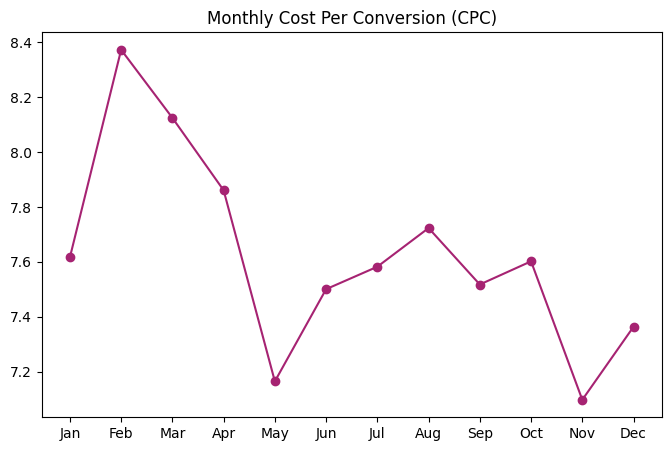

In [37]:
plt.figure(figsize=(8, 5))
plt.title('Monthly Cost Per Conversion (CPC)')
monthly_df = df.groupby('month')[
    ['Facebook Ad Conversions', 'Cost per Facebook Ad']
].sum()
monthly_df['Cost per Conversion'] = (
    monthly_df['Cost per Facebook Ad'] / monthly_df['Facebook Ad Conversions']
)
plt.plot(month_names, monthly_df['Cost per Conversion'], '-o', color='#A62372')
plt.show()

### Monthly Cost Per Conversion — Insights & Recommendations

- **Highest Cost (Worst Efficiency):** **February** peaks sharply at **8.37** per conversion (driven by the lowest conversion volume of the year), followed by **March** (~8.13).
- **Lowest Cost (Best Efficiency):** **November** achieves the lowest cost per conversion at **7.11**, closely followed by **May** (7.17) and **December** (~7.36).
- **Mid-Year Stability:** From **June to October**, cost per conversion stays steady within a narrow **7.50 – 7.73** range even as total conversions climb.

**Recommendations:**
- Reallocate budget toward **May, November, and December**, where acquisition costs are lowest and efficiency is highest.
- Audit ad targeting, creatives, and bidding strategies in **February and March** to prevent high cost-per-conversion spikes during low-volume months.

In [38]:
from statsmodels.tsa.stattools import coint

score, p_value, _ = coint(
    df['Cost per Facebook Ad'], df['Facebook Ad Conversions']
)
print('Cointegration test score:', score)
print('P-value:', p_value)

if p_value < 0.05:
  print('\np-value is less than significance value, Reject the null hypothesis')
else:
  print(
      '\np-value is greater than significance value, Accept the null hypothesis'
  )

Cointegration test score: -2.4601704147903254
P-value: 0.29691177672027125

p-value is greater than significance value, Accept the null hypothesis


### Cointegration Test Result (Facebook Ad Cost vs. Conversions)

- **Cointegration Test Score:** -2.46
- **p-value:** 0.2969 (> 0.05)

**Conclusion:** Fail to reject (accept) the null hypothesis—there is no statistically significant long-term equilibrium relationship between **Cost per Facebook Ad** and **Facebook Ad Conversions** over time.

**Recommendations:**
- Simply increasing total ad spend does not guarantee a proportional long-term rise in conversions.
- Focus on optimizing **ad quality, audience targeting, and high-performing days/months** rather than relying purely on higher budget allocation.

### Key Findings
- **Higher Conversions on Facebook:** Facebook averages **11.63** daily conversions vs. **4.99** on AdWords (`t = 33.91`, `p = 1.90e-140`, null hypothesis rejected).
- **Stronger Click-to-Conversion Link:** Facebook clicks correlate strongly with conversions (`r = 0.88`), whereas AdWords shows a weaker link (`r = 0.45`).
- **Predictive Fit:** A linear regression model on Facebook clicks explains **76.81%** of conversion variance (`MSE = 2.41`), predicting **12.56** conversions at 50 clicks and **16.95** at 80 clicks.
- **Seasonality & Day Trends:** Conversions peak on **Sundays/Mondays** and in **Q3–Q4 (Sep–Dec)**, while cost per conversion is lowest in **May, Nov, and Dec** and highest in **Feb–Mar**.
- **Long-Term Cost Dynamics:** Cointegration testing (`score = -2.46`, `p = 0.2969`) shows no long-term equilibrium between Facebook ad cost and conversions—higher spend alone does not guarantee proportional gains.

### Core Recommendations
- Shift budget toward **Facebook** and concentrate spend on high-converting days (**Sun–Mon**) and efficient months (**May, Nov, Dec**).
- Focus on **creative quality, audience targeting, and bidding optimization** rather than relying purely on higher ad spend.